1. Desarrollar una función basada en ciclos que permita
realizar la transformada discreta de Fourier en 2D,
aplicando el algoritmo con imágenes en escala de
grises. Ejemplos de imágenes: “rectOne.pgm”,
“circulo.pgm”, “liraImpulsivo.pgm”.

2. Visualizar el espectro de las imágenes usando escala
logarítmica.

3. Desarrollar una función basada en ciclos, que realice
la DFT en 2D usando la propiedad de separabilidad.

In [28]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

os.makedirs('results', exist_ok=True)

1. Desarrollar una función basada en ciclos que permita
realizar la transformada discreta de Fourier en 2D,
aplicando el algoritmo con imágenes en escala de
grises. Ejemplos de imágenes: “rectOne.pgm”,
“circulo.pgm”, “liraImpulsivo.pgm”.

$$
F(u,v)=\frac{1}{MN}
\sum_{x=0}^{M-1}\sum_{y=0}^{N-1}
f(x,y)e^{-i2\pi\left(\frac{ux}{M}+\frac{vy}{N}\right)}
$$

In [29]:
def dft2d(imagen):
    # Dimensiones de la imagen
    # M = número de filas, N = número de columnas
    M, N = imagen.shape

    # Crear una matriz de ceros compleja para almacenar la DFT
    resultado = np.zeros((M, N), dtype=complex)

    # Calcular la DFT bidimensional
    # recorrer cada frecuencia u y v
    for u in range(M):
        for v in range(N):
            suma = 0j # Inicializar la suma como un número complejo
            for x in range(M):
                for y in range(N):
                    # Calcular angulo
                    angulo = -2 * np.pi * ((u * x / M) + (v * y / N))
                    exponencial = np.exp(angulo * 1j) # e^(i*angulo)
                    pixel = imagen[x, y] # Obtener el valor del pixel
                    suma += pixel * exponencial # Acumular la suma

            # Normalizar la DFT y guardar coeficiente en la matriz resultado
            resultado[u, v] = suma/(M * N) # Normalizar la DFT

    return resultado

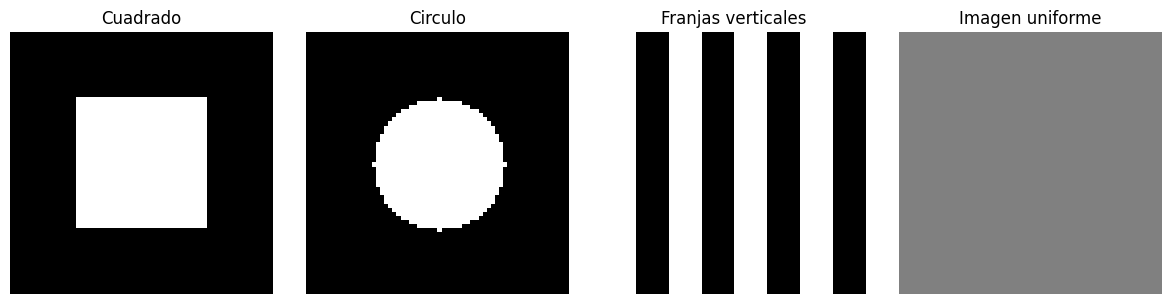

In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

tamano = 64

# 1. Cuadrado blanco de 32x32
cuadrado = np.zeros((tamano, tamano), dtype=np.float64)
cuadrado[16:48, 16:48] = 255

# 2. Circulo blanco de radio 16
circulo = np.zeros((tamano, tamano), dtype=np.float64)

centro = tamano // 2
radio = 16

for i in range(tamano):
    for j in range(tamano):
        if (i - centro)**2 + (j - centro)**2 <= radio**2:
            circulo[i, j] = 255

# 3. Franjas verticales
franjas = np.zeros((tamano, tamano), dtype=np.float64)

for i in range(tamano):
    for j in range(tamano):
        if (j // 8) % 2 == 0:
            franjas[i, j] = 255

# 4. Imagen uniforme
uniforme = np.full((tamano, tamano), 128, dtype=np.float64)

imagenes = [cuadrado, circulo, franjas, uniforme]

titulos = [
    "Cuadrado",
    "Circulo",
    "Franjas verticales",
    "Imagen uniforme"
]

fig, axs = plt.subplots(1, 4, figsize=(12, 3))

for ax, img, titulo in zip(axs, imagenes, titulos):
    ax.imshow(
        img,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.savefig("results/imagenes_sinteticas.png", dpi=200)
plt.show()

In [30]:
import time

imagenes = [cuadrado, circulo, franjas, uniforme]

titulos = [
    "Cuadrado",
    "Circulo",
    "Franjas verticales",
    "Imagen uniforme"
]

transformadas = []

# Calcular la DFT de las cuatro imágenes
for titulo, imagen_actual in zip(titulos, imagenes):

    inicio = time.perf_counter()

    transformada = dft2d(imagen_actual)
    transformadas.append(transformada)

    tiempo = time.perf_counter() - inicio

    # Comparar con NumPy para validar el resultado
    referencia = np.fft.fft2(imagen_actual) / imagen_actual.size
    correcto = np.allclose(transformada, referencia, atol=1e-10)

    print(f"{titulo}:")
    print(f"  Tiempo: {tiempo:.2f} segundos")
    print(f"  Dimensiones: {transformada.shape}")
    print(f"  Coincide con NumPy: {correcto}")
    print()

Cuadrado:
  Tiempo: 16.80 segundos
  Dimensiones: (64, 64)
  Coincide con NumPy: True

Circulo:
  Tiempo: 16.74 segundos
  Dimensiones: (64, 64)
  Coincide con NumPy: True

Franjas verticales:
  Tiempo: 16.82 segundos
  Dimensiones: (64, 64)
  Coincide con NumPy: True

Imagen uniforme:
  Tiempo: 16.85 segundos
  Dimensiones: (64, 64)
  Coincide con NumPy: True



### Análisis de resultados — Punto 1

Se implementó una función para calcular la Transformada Discreta de Fourier en 2D mediante cuatro ciclos anidados, utilizando directamente su definición matemática.

Para comprobar su funcionamiento se utilizaron cuatro imágenes sintéticas en escala de grises de 64×64 píxeles: un cuadrado, un círculo, franjas verticales y una imagen uniforme.

Los tiempos de ejecución estuvieron entre 16,74 y 16,85 segundos por imagen. Estos tiempos fueron similares porque el algoritmo recorre todos los píxeles para calcular cada coeficiente de frecuencia, independientemente del contenido de la imagen.

Posteriormente, se compararon las transformadas calculadas manualmente con los resultados de `np.fft.fft2()`, teniendo en cuenta la normalización utilizada. Las cuatro comparaciones devolvieron `True`, lo que permitió verificar que la implementación produce resultados numéricamente equivalentes a los de NumPy.

se logró implementar y validar la DFT 2D mediante ciclos, comprobando que transforma las imágenes del dominio espacial al dominio de la frecuencia. También se observó que la implementación directa requiere un tiempo de procesamiento considerable, incluso con imágenes pequeñas.

## punto 2
Visualizar el espectro de las imágenes usando escala
logarítmica.

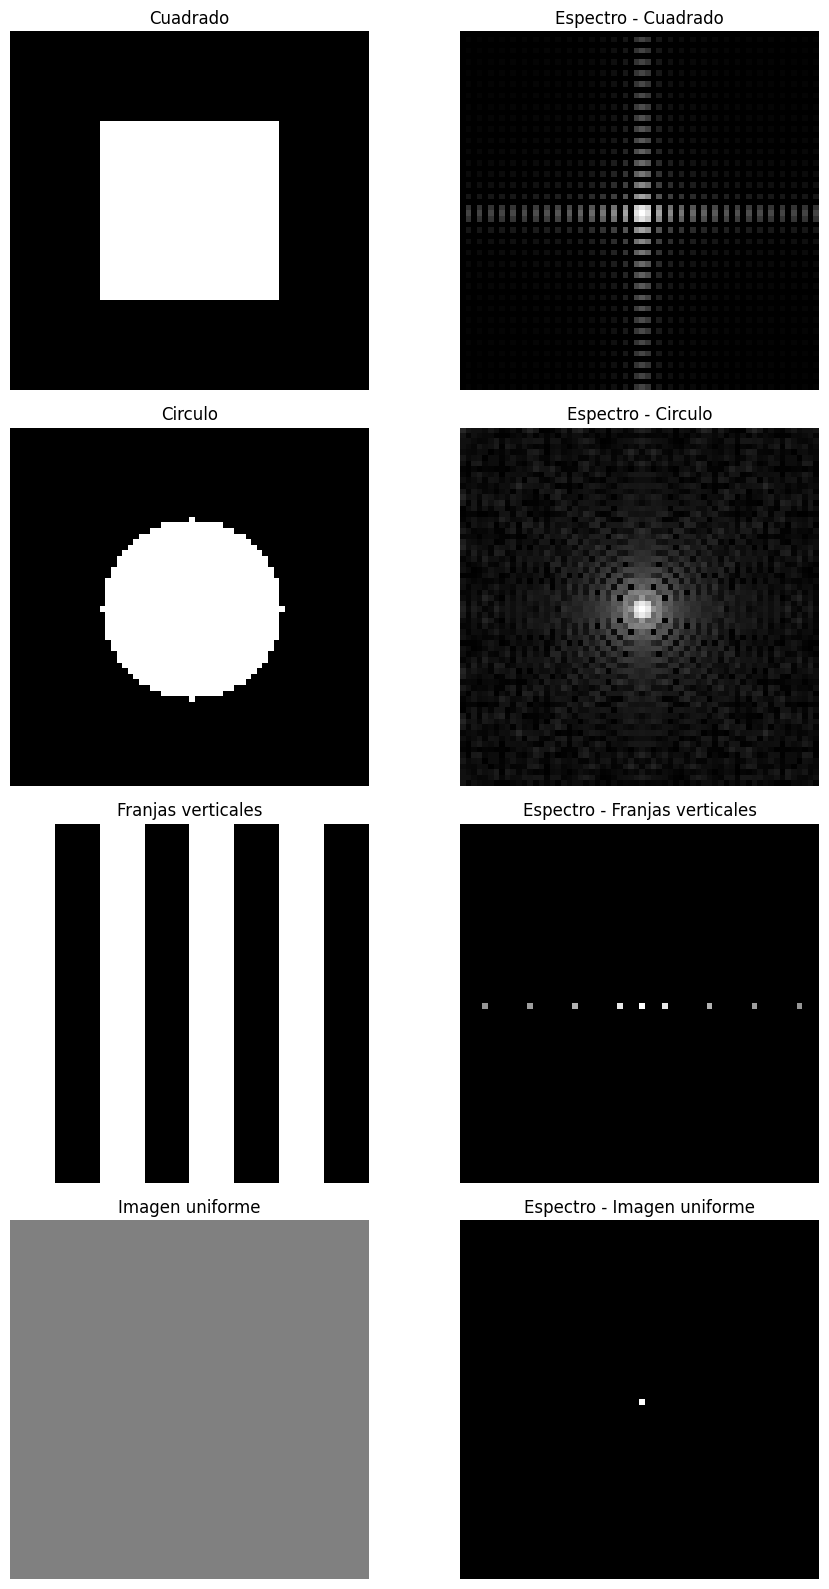

In [32]:
fig, axs = plt.subplots(4, 2, figsize=(10, 16))

for i, (imagen_actual, transformada, titulo) in enumerate(
    zip(imagenes, transformadas, titulos)
):
    # Centrar la transformada
    centrada = np.fft.fftshift(transformada)

    # Calcular el espectro logaritmico
    espectro = np.log1p(np.abs(centrada))

    # Imagen original
    axs[i, 0].imshow(
        imagen_actual,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )
    axs[i, 0].set_title(titulo)
    axs[i, 0].axis("off")

    # Espectro de Fourier
    axs[i, 1].imshow(
        espectro,
        cmap="gray",
        interpolation="nearest"
    )
    axs[i, 1].set_title(f"Espectro - {titulo}")
    axs[i, 1].axis("off")

plt.tight_layout()
plt.savefig("results/espectros_dft.png", dpi=200)
plt.show()

### Análisis de resultados — Punto 2

Se visualizaron los espectros de Fourier de cuatro imágenes en escala de grises de 64×64 píxeles, utilizando la magnitud de la transformada y una escala logarítmica para facilitar la identificación de las diferentes componentes de frecuencia. También se centraron los espectros para ubicar la frecuencia cero en el centro de cada representación.

En la imagen del **cuadrado**, el espectro presenta una estructura en forma de cruz con múltiples puntos brillantes y oscuros, relacionada con sus bordes horizontales y verticales. La presencia de varios puntos se debe a los cambios bruscos de intensidad entre el cuadrado blanco y el fondo negro.

En el **círculo**, se observa una distribución aproximadamente circular con anillos alrededor del centro. Esto ocurre debido a la simetría radial de la figura, que también se manifiesta en su espectro de frecuencias.

En la imagen de **franjas verticales**, aparecen puntos brillantes distribuidos sobre el eje horizontal. Esto sucede porque los cambios de intensidad se presentan de manera periódica de izquierda a derecha. Los distintos puntos corresponden a las frecuencias que componen ese patrón repetitivo.

Finalmente, la **imagen uniforme** presenta únicamente un punto brillante en el centro del espectro, debido a que todos sus píxeles tienen la misma intensidad y no existen variaciones espaciales. Este punto representa la componente continua o frecuencia cero.

**En conclusión**, los espectros obtenidos muestran que la Transformada de Fourier permite identificar características de las imágenes a partir de sus componentes de frecuencia. Las formas, los bordes, la orientación y la repetición de patrones producen distribuciones diferentes en el espectro, lo que permite analizar las imágenes desde una perspectiva distinta al dominio espacial.

## Punto 3
Desarrollar una función basada en ciclos, que realice
la DFT en 2D usando la propiedad de separabilidad.

In [33]:
# Funcion que hace solo la transformada en 1D

def dft1d(vector):
    N = len(vector)

    resultado = np.zeros(N, dtype=complex)

    for k in range(N):
        suma = 0j

        for n in range(N):
            angulo = -2 * np.pi * k * n / N
            exponencial = np.exp(1j * angulo)

            suma += vector[n] * exponencial

        resultado[k] = suma / N

    return resultado


# Funcion que hace la transformada en 2D usando la transformada en 1D

def dft2d_separable(imagen):
    M, N = imagen.shape

    # Etapa 1: DFT sobre cada fila
    transformada_filas = np.zeros((M, N), dtype=complex)

    for fila in range(M):
        transformada_filas[fila, :] = dft1d(
            imagen[fila, :]
        )

    # Etapa 2: DFT sobre cada columna
    resultado = np.zeros((M, N), dtype=complex)

    for columna in range(N):
        resultado[:, columna] = dft1d(
            transformada_filas[:, columna]
        )

    return resultado

In [35]:
transformadas_separables = []

for titulo, imagen_actual, transformada_directa in zip( titulos, imagenes, transformadas):

    inicio = time.perf_counter()

    resultado = dft2d_separable(imagen_actual)

    tiempo = time.perf_counter() - inicio

    transformadas_separables.append(resultado)

    correcto = np.allclose(
        resultado,
        transformada_directa,
        atol=1e-10
    )

    diferencia = np.max(
        np.abs(resultado - transformada_directa)
    )

    print(f"{titulo}:")
    print(f"  Tiempo: {tiempo:.4f} segundos")
    print(f"  Coincide con DFT directa: {correcto}")
    print(f"  Diferencia maxima: {diferencia:.2e}")
    print()

Cuadrado:
  Tiempo: 0.4783 segundos
  Coincide con DFT directa: True
  Diferencia maxima: 6.43e-13

Circulo:
  Tiempo: 0.4827 segundos
  Coincide con DFT directa: True
  Diferencia maxima: 5.42e-13

Franjas verticales:
  Tiempo: 0.5200 segundos
  Coincide con DFT directa: True
  Diferencia maxima: 6.38e-13

Imagen uniforme:
  Tiempo: 0.4889 segundos
  Coincide con DFT directa: True
  Diferencia maxima: 6.04e-13



###Análisis de resultados — Punto 3

Se implementó la Transformada Discreta de Fourier en 2D utilizando la propiedad de separabilidad. Para ello, se desarrolló una función que calcula manualmente la DFT en una dimensión mediante ciclos y posteriormente se aplicó sobre las filas y columnas de cada imagen.

El algoritmo se probó con las cuatro imágenes de 64×64 píxeles utilizadas anteriormente: cuadrado, círculo, franjas verticales e imagen uniforme.

Los tiempos de ejecución estuvieron entre 0,4783 y 0,5200 segundos, valores considerablemente inferiores a los obtenidos con la implementación directa, que tardó aproximadamente 17 segundos por imagen.

Al comparar ambos métodos, se observó una mejora de velocidad de alrededor de 34 veces. Esto sucede porque la separabilidad permite calcular la transformada mediante dos etapas unidimensionales, reduciendo la cantidad de operaciones necesarias.

Además, las comparaciones entre ambas implementaciones devolvieron True en los cuatro casos, con diferencias máximas del orden de (10^{-13}). Estas pequeñas diferencias se deben a la precisión numérica y no representan cambios significativos en los resultados.

En conclusión, la propiedad de separabilidad permitió calcular la misma DFT 2D de manera mucho más eficiente, sin perder precisión. Esto demuestra la importancia de aprovechar las propiedades matemáticas de un algoritmo para reducir su costo computacional.